# Exercice 1 - Regression : prediction du tarif d'un trajet Uber

Objectif : predire le montant d'une course Uber a partir de la distance, de l'heure et du jour de la semaine.

Jeu de donnees : *Uber Fares Dataset* (Kaggle). Le fichier `data/uber.csv` reprend le schema du dataset Kaggle (coordonnees GPS, horodatage, montant). Il suffit de le remplacer par le fichier Kaggle pour refaire l'analyse sur les donnees reelles.

## Etape 1 - Chargement et exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

data = pd.read_csv('data/uber.csv')
data.head()

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2014-09-25 18:11:29.0,10.47,2014-09-25 18:11:29,-73.960858,40.773090,-74.008096,40.762132,3
1,2014-09-20 17:53:55.1,14.05,2014-09-20 17:53:55,-74.001200,40.694683,-73.929473,40.666964,6
2,2014-02-08 22:49:17.2,11.53,2014-02-08 22:49:17,-73.947486,40.742810,-73.893597,40.752807,5
3,2014-04-08 00:29:13.3,9.08,2014-04-08 00:29:13,-73.941783,40.717281,-73.966643,40.735613,6
4,2014-10-16 11:28:24.4,8.79,2014-10-16 11:28:24,-74.028531,40.835910,-73.980489,40.850447,5


In [2]:
# Types des colonnes et nombre de valeurs non nulles
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   key                50000 non-null  str    
 1   fare_amount        50000 non-null  float64
 2   pickup_datetime    50000 non-null  str    
 3   pickup_longitude   50000 non-null  float64
 4   pickup_latitude    50000 non-null  float64
 5   dropoff_longitude  49000 non-null  float64
 6   dropoff_latitude   49000 non-null  float64
 7   passenger_count    50000 non-null  int64  
dtypes: float64(5), int64(1), str(2)
memory usage: 3.1 MB


In [3]:
# Comptage des valeurs manquantes par colonne
data.isnull().sum()

key                     0
fare_amount             0
pickup_datetime         0
pickup_longitude        0
pickup_latitude         0
dropoff_longitude    1000
dropoff_latitude     1000
passenger_count         0
dtype: int64

In [4]:
# Statistiques descriptives : on repere deja des tarifs negatifs et
# des valeurs maximales aberrantes sur fare_amount.
data.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,50000.000000,50000.000000,50000.000000,49000.000000,49000.000000,50000.000000
mean,11.548735,-73.970016,40.749762,-73.970131,40.749948,3.501620
std,32.185010,0.030079,0.030144,0.042599,0.042447,1.714473
min,-5.000000,-74.101673,40.632796,-74.145304,40.564750,1.000000
25%,6.570000,-73.990212,40.729496,-73.998904,40.721500,2.000000
50%,9.050000,-73.970158,40.749598,-73.970112,40.750075,4.000000
75%,11.890000,-73.949929,40.770097,-73.941570,40.778538,5.000000
max,599.262746,-73.819783,40.885202,-73.801457,40.934615,6.000000


## Etape 2 - Nettoyage et preparation

On enleve les lignes incompletes, les tarifs incoherents (negatifs ou nuls) et les valeurs extremes. On calcule ensuite la distance du trajet a partir des coordonnees GPS (formule de haversine) et on derive l'heure et le jour de la semaine depuis l'horodatage.

In [5]:
# Suppression des valeurs manquantes (destination absente notamment)
data = data.dropna()

# Un tarif doit etre strictement positif
data = data[data['fare_amount'] > 0]

print('Lignes restantes apres premier nettoyage :', len(data))

Lignes restantes apres premier nettoyage : 48485


In [6]:
def haversine(lon1, lat1, lon2, lat2):
    """Distance en km entre deux points GPS."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

data['distance'] = haversine(data['pickup_longitude'], data['pickup_latitude'],
                             data['dropoff_longitude'], data['dropoff_latitude'])

In [7]:
# Variables temporelles derivees de l'horodatage
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

In [8]:
# Retrait des valeurs aberrantes : on borne le tarif et la distance
# en coupant les 1 % extremes, et on garde des trajets plausibles.
q_low, q_high = data['fare_amount'].quantile([0.01, 0.99])
data = data[(data['fare_amount'] >= q_low) & (data['fare_amount'] <= q_high)]
data = data[(data['distance'] > 0) & (data['distance'] < 50)]

print('Lignes conservees pour la modelisation :', len(data))
data[['fare_amount', 'distance', 'hour', 'day_of_week']].describe()

Lignes conservees pour la modelisation : 47517


,fare_amount,distance,hour,day_of_week
count,47517.000000,47517.000000,47517.000000,47517.000000
mean,9.464540,3.691552,11.488162,3.007471
std,3.697863,1.901632,6.917701,1.994765
min,2.110000,0.010773,0.000000,0.000000
25%,6.700000,2.254905,5.000000,1.000000
50%,9.100000,3.452941,12.000000,3.000000
75%,11.860000,4.886525,17.000000,5.000000
max,21.240000,11.599130,23.000000,6.000000


## Etape 3 - Separation des donnees

On predit `fare_amount` a partir de la distance, de l'heure, du jour de la semaine et du nombre de passagers. 80 % des donnees servent a l'entrainement, 20 % au test.

In [9]:
from sklearn.model_selection import train_test_split

features = ['distance', 'hour', 'day_of_week', 'passenger_count']
X = data[features]
y = data['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(38013, 4) (9504, 4)


## Etape 4 - Entrainement d'une regression lineaire

In [10]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Coefficients : effet de chaque variable sur le tarif
pd.Series(lr.coef_, index=features)

distance           1.760969
hour               0.010349
day_of_week       -0.000992
passenger_count    0.002794
dtype: float64

## Etape 5 - Evaluation du modele

On mesure l'erreur absolue moyenne (MAE), l'erreur quadratique moyenne (RMSE) et le coefficient de determination R2.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluer(nom, y_vrai, y_prev):
    mae = mean_absolute_error(y_vrai, y_prev)
    rmse = np.sqrt(mean_squared_error(y_vrai, y_prev))
    r2 = r2_score(y_vrai, y_prev)
    print(f'{nom:18s} MAE={mae:.3f}  RMSE={rmse:.3f}  R2={r2:.3f}')
    return mae, rmse, r2

evaluer('Regression lin.', y_test, y_pred_lr)

Regression lin.    MAE=1.246  RMSE=1.557  R2=0.823


(1.2459474636017471, np.float64(1.5566876752074028), 0.8225947451038633)

## Etape 6 - Amelioration avec une foret aleatoire

La relation n'est pas purement lineaire (effet des heures de pointe). On compare avec un `RandomForestRegressor`.

In [12]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

evaluer('Regression lin.', y_test, y_pred_lr)
evaluer('Foret aleatoire', y_test, y_pred_rf)

Regression lin.    MAE=1.246  RMSE=1.557  R2=0.823
Foret aleatoire    MAE=1.256  RMSE=1.574  R2=0.819


(1.2558876578282827, np.float64(1.5735918196430205), 0.8187209217137608)

## Etape 7 - Visualisation des resultats

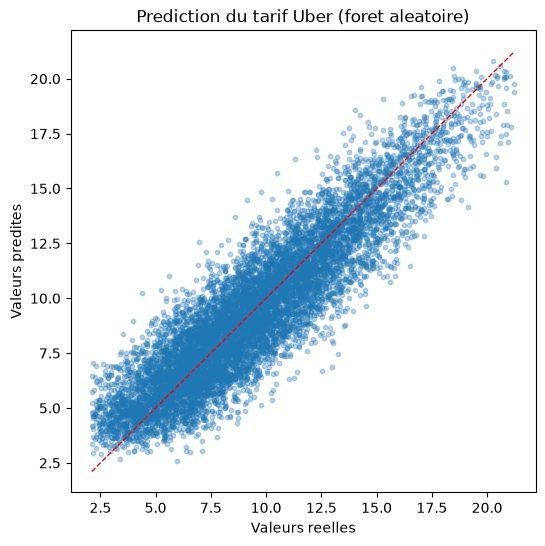

In [13]:
# Valeurs predites par la foret aleatoire face aux valeurs reelles.
# Plus les points sont proches de la diagonale, meilleure est la prediction.
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3, s=10)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', linewidth=1)
plt.xlabel('Valeurs reelles')
plt.ylabel('Valeurs predites')
plt.title('Prediction du tarif Uber (foret aleatoire)')
plt.show()

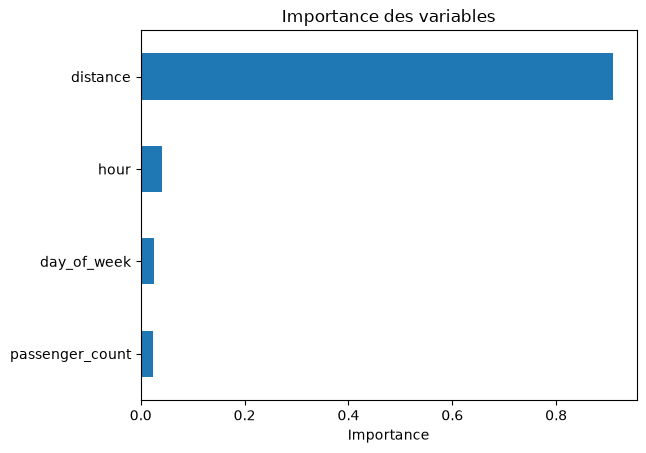

In [14]:
# Importance des variables selon la foret aleatoire
importances = pd.Series(rf.feature_importances_, index=features).sort_values()
importances.plot(kind='barh')
plt.title('Importance des variables')
plt.xlabel('Importance')
plt.show()

## Conclusion

La distance est de loin la variable la plus explicative du tarif, ce qui est attendu. La regression lineaire explique deja environ 82 % de la variance (R2 proche de 0.82). La foret aleatoire obtient ici des scores quasi identiques, sans gain reel, pour un temps de calcul bien plus eleve : sur ce jeu de donnees, la regression lineaire est donc preferable (plus simple, plus rapide et interpretable). Sur les donnees reelles de Kaggle, plus bruitees et avec davantage de variables, la foret aleatoire pourrait en revanche faire la difference.